# 01 · Cleaning, canonical schema & data quality

**Source:** `data/raw/chemist.csv`, a Wikidata Query Service *card-view* export of people with a chemistry-related occupation (P106).
The raw file is never modified; everything below is produced by `python -m chemkg.pipeline data`.

### Assumptions (stated up front)
1. **The QID comes from `explore href`.** `card-view-value` usually holds the English label (= the name we display) and holds the bare QID only for items with no English label.
2. **Cells are parsed by content type, not position.** Fields are skipped when missing, so columns shift. In 18 rows the keys are also out of step with their values, so a cell's meaning comes from its *content* (date / Wikipedia URL / known occupation / otherwise country). Key cells only decide birth vs. death.
3. **"1 January YYYY" means year precision.** That's how Wikidata renders year-precision dates. Real 1 January birthdays get misclassified, which slightly overstates imprecision.
4. **BCE years are negative, with no year zero.** Lifespans account for that.
5. **"Likely living" = no death date and born after 1916** (reference year 2026 minus 110). People born in 1916 or earlier with no death date are flagged and excluded from survival analysis, not treated as censored.
6. **Flag, don't drop.** Implausible lifespans, fictional entries and non-state citizenships stay in the tables with `quality_flags`, and each analysis decides what to exclude.

In [1]:
import json, itertools, collections
import pandas as pd
from chemkg.paths import PROCESSED
from chemkg import countries
pd.set_option("display.max_colwidth", 80)
people = pd.read_parquet(PROCESSED/"people.parquet")
pc = pd.read_parquet(PROCESSED/"person_country.parquet")
po = pd.read_parquet(PROCESSED/"person_occupation.parquet")
pairs = pd.read_parquet(PROCESSED/"person_country_pairs.parquet")
q = json.loads((PROCESSED/"quality.json").read_text())
{k: q[k] for k in ["raw", "people", "unique_names", "fill_rates_pct", "living_likely", "multi_occupation_people"]}

{'raw': {'rows': 15635, 'misaligned_rows': 18},
 'people': 11903,
 'unique_names': 11883,
 'fill_rates_pct': {'birth_year': 89.7,
  'death_year': 60.8,
  'country': 80.5,
  'occupation': 100.0,
  'wikipedia_url': 100.0},
 'living_likely': 3439,
 'multi_occupation_people': 1079}

**11,903 people vs. 11,883 names:** 20 pairs of distinct Wikidata items share a name (namesakes). Counting by QID is the correct unit.

**Fill rates are per person.** Per *row* they're higher (birth 92%, country 84%), because people with more countries and occupations take up more rows.

In [2]:
people[["qid","name","birth_year","birth_precision","death_year","lifespan","is_living_likely","primary_domain","n_country_affiliations","quality_flags"]].sample(8, random_state=1)

,qid,name,birth_year,birth_precision,death_year,lifespan,is_living_likely,primary_domain,n_country_affiliations,quality_flags
10808,Q80196494,Helena Kandárová,1977,year,<NA>,<NA>,True,Life & medicinal chemistry,0,"[birth_year_precision, missing_country]"
7171,Q16336332,Ding Kuiling,1966,day,<NA>,<NA>,True,General chemistry,1,[]
11827,Q133826742,Herbert R. Moody,1869,day,1947,78,False,General chemistry,0,[missing_country]
6626,Q12881128,Michael K. Stefanidis,1868,day,1957,89,False,General chemistry,1,[]
5747,Q7323855,Richard B. Frankel,<NA>,None,<NA>,<NA>,False,General chemistry,0,"[missing_birth, missing_country]"
4883,Q5927118,Hubert Alyea,1903,day,1996,93,False,General chemistry,1,[]
9741,Q48574386,Pier Giorgio Righetti,1941,day,<NA>,<NA>,True,Life & medicinal chemistry,1,[]
2353,Q908655,John Mercer,1791,day,1866,75,False,General chemistry,1,[]


## Quality flags

In [3]:
pd.DataFrame({"n": pd.Series(q["flags"]), "definition": pd.Series(q["flag_definitions"])}).sort_values("n", ascending=False)

,n,definition
missing_country,2323.0,no country of citizenship
birth_year_precision,2183.0,birth rendered as '1 January' = Wikidata year precision (a true 1 Jan birthd...
missing_birth,1228.0,no birth date in Wikidata
death_year_precision,740.0,death rendered as '1 January' = year precision
conflicting_birth_dates,192.0,more than one birth date statement; most precise then earliest kept
conflicting_death_dates,133.0,more than one death date statement; most precise then earliest kept
death_missing_presumed_dead,38.0,no death date but born <= 1916; excluded from survival analysis
no_english_label,24.0,no English label; name decoded from Wikipedia URL
misaligned_source_row,15.0,a source row had keys out of step with values; parsed by content type
lifespan_over_110,3.0,lifespan > 110 years: likely date error


In [4]:
for flag in ["lifespan_over_110", "lifespan_under_15", "bce_date", "misaligned_source_row", "suspected_non_human", "non_country_citizenship"]:
    print(f"\n== {flag}")
    print(pd.DataFrame(q["flagged_examples"][flag]).to_string(index=False))


== lifespan_over_110
      qid            name      birth_date      death_date  lifespan
 Q3147472  Ibn Al-Thahabi  1 January 0901  1 January 1033       132
 Q4406004 Alexander Imich 4 February 1903     8 June 2014       111
Q23303280    Ernest Noble  1 January 1901 17 October 2017       116

== lifespan_under_15
      qid                name     birth_date       death_date  lifespan
  Q902388 William Cruickshank 1 January 1800 14 February 1809         9
Q17021355 Jean-Claude Bradley 1 January 2000      13 May 2014        14
Q27907233    P. M. de Respour 1 January 1650   1 January 1650         0

== bce_date
     qid     name         birth_date         death_date  lifespan
 Q743993 Crateuas 1 January 0201 BCE 1 January 0101 BCE     100.0
Q4355213  Tapputi 1 January 1201 BCE               None       NaN

== misaligned_source_row
      qid                 name         birth_date     death_date  lifespan
  Q158940                 Bane               None           None       NaN
  Q421675

The implausible lifespans include obvious errors: *P. M. de Respour* has birth and death both in 1650 (lifespan 0), and *Ibn Al-Thahabi* lived 132 years. *William Cruickshank*'s 9-year life suggests the wrong birth year was entered. These go to the anomaly-detection analysis (Phase 3.5); they're not fixed by hand.

## Date precision & birth-year coverage

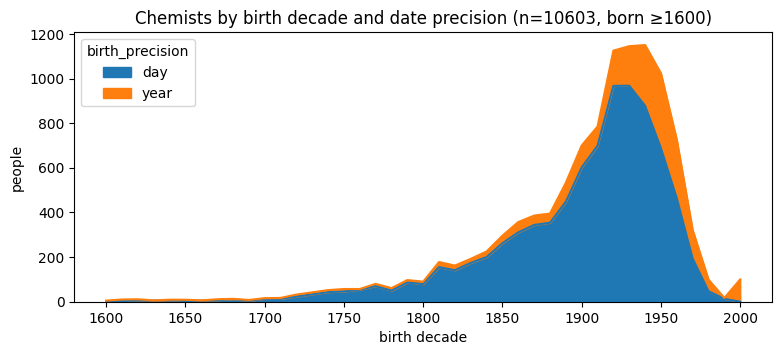

In [5]:
ax = people.dropna(subset=["birth_year"]).query("birth_year >= 1600").assign(
    decade=lambda d: d.birth_year // 10 * 10).groupby(["decade","birth_precision"]).size().unstack(fill_value=0).plot(
    kind="area", figsize=(9,3.5), title="Chemists by birth decade and date precision (n=%d, born ≥1600)" % people.birth_year.ge(1600).sum())
ax.set_xlabel("birth decade"); ax.set_ylabel("people");

## Country mapping

There are 291 distinct Wikidata citizenship labels: 138 modern states, 141 historical entities, 9 subnational units and 3 non-states. Every label maps to a **primary modern successor** (used for maps and aggregation) and a **territory set** (every modern state that covers part of its territory).

In [6]:
cmap = countries.load_country_map()
used = pc.country_label.value_counts().rename("people")
tbl = cmap.set_index("country_label").join(used, how="inner").sort_values("people", ascending=False)
tbl["territory"] = tbl.territory.map(lambda s: "|".join(sorted(s)))
tbl.query("kind != 'modern'")[["people","kind","iso3","modern_name","region","territory","note"]].head(40)

,people,kind,iso3,modern_name,region,territory,note
country_label,,,,,,,
United Kingdom of Great Britain and Ireland,483,historical,GBR,United Kingdom,Western Europe,GBR|IRL,1801-1922
Soviet Union,258,historical,RUS,Russia,Former USSR,ARM|AZE|BLR|EST|GEO|KAZ|KGZ|LTU|LVA|MDA|RUS|TJK|TKM|UKR|UZB,primary successor = Russia
Russian Empire,193,historical,RUS,Russia,Former USSR,ARM|AZE|BLR|EST|FIN|GEO|KAZ|KGZ|LTU|LVA|MDA|POL|RUS|TJK|TKM|UKR|UZB,primary successor = Russia
British Raj,111,historical,IND,India,South Asia,BGD|IND|MMR|PAK,primary successor = India
Kingdom of Prussia,96,historical,DEU,Germany,Western Europe,DEU|LTU|POL|RUS,primary successor = Germany
German Reich,96,historical,DEU,Germany,Western Europe,DEU|FRA|POL|RUS,1871-1945 (Wikidata umbrella item)
Dominion of India,92,historical,IND,India,South Asia,IND,1947-1950
Kingdom of Great Britain,72,historical,GBR,United Kingdom,Western Europe,GBR,1707-1800
Kingdom of Italy,69,historical,ITA,Italy,Southern Europe,ITA,NaN


### Name changes vs. real multi-country affiliations
Two labels on the same person are a **name change** when their territory sets intersect (Russian Empire / Soviet Union / Russia), and a **multi-country affiliation** when they don't (Germany / United States). Labels are merged into connected components, so a person with two or more components is a migration candidate. P27 statements carry no order, so *direction* is resolved in the migration analysis using place of birth (P19) from enrichment.

Known limitation: border changes between *modern* states (e.g. Silesia: Germany → Poland) look like migration. The one systematic case, Pakistan / Bangladesh before 1971, is handled explicitly.

In [7]:
pairs.relation.value_counts()

relation
name_change      1403
multi_country     824
Name: count, dtype: int64

In [8]:
pairs.groupby(["relation","label_a","label_b"]).size().rename("people").reset_index().sort_values("people", ascending=False).groupby("relation").head(12)

,relation,label_a,label_b,people
559,name_change,United Kingdom,United Kingdom of Great Britain and Ireland,211
364,name_change,British Raj,India,93
393,name_change,Dominion of India,India,92
363,name_change,British Raj,Dominion of India,84
525,name_change,Russian Empire,Soviet Union,84
520,name_change,Russia,Soviet Union,80
473,name_change,Kingdom of Great Britain,United Kingdom of Great Britain and Ireland,47
402,name_change,Empire of Japan,Japan,46
466,name_change,Italy,Kingdom of Italy,43
190,multi_country,Germany,United States,42


## Occupation taxonomy

In [9]:
dom = po.groupby(["domain","occupation"]).qid.nunique().rename("people").reset_index().sort_values(["domain","people"], ascending=[True,False])
dom.groupby("domain").agg(people=("people","sum"), occupations=("occupation", lambda s: ", ".join(s)))

,people,occupations
domain,,
Analytical & measurement,35,"analytical chemist, spectroscopist, mass spectrometrist, chemometrician"
Applied & industrial,610,"chemical engineer, chemical technologist, agricultural chemist, food chemist..."
Earth & environment,220,"geochemist, atmospheric chemist, biogeochemist, environmental chemist, marin..."
General chemistry,8354,"chemist, chemistry didactician"
Life & medicinal chemistry,3302,"biochemist, pharmacologist, toxicologist, pharmaceutical chemist, bioinorgan..."
Physical & theoretical,455,"crystallographer, physical chemist, theoretical chemist, electrochemist, com..."
Synthesis & materials,82,"organic chemist, polymer chemist, inorganic chemist, materials chemist, ster..."


In [10]:
c = collections.Counter()
for _, g in po.groupby("qid").occupation:
    c.update(itertools.combinations(sorted(g), 2))
pd.DataFrame(c.most_common(10), columns=["pair","people"])

,pair,people
0,"(biochemist, chemist)",559
1,"(chemist, pharmacologist)",112
2,"(chemical engineer, chemist)",87
3,"(chemist, crystallographer)",68
4,"(biochemist, pharmacologist)",66
5,"(chemist, physical chemist)",57
6,"(chemist, geochemist)",27
7,"(biochemist, crystallographer)",27
8,"(chemist, organic chemist)",21
9,"(chemist, theoretical chemist)",17


In [11]:
people.primary_domain.value_counts()

primary_domain
General chemistry             7381
Life & medicinal chemistry    3150
Applied & industrial           602
Physical & theoretical         443
Earth & environment            214
Synthesis & materials           79
Analytical & measurement        34
Name: count, dtype: int64

## Caveats carried forward
- **Notability bias.** Inclusion requires a Wikidata item *and* an English Wikipedia article, which over-represents anglophone, Western and 20th-century chemists.
- **Under-specified occupations.** "chemist" is often the only occupation recorded, so domain shares are lower bounds for specialties.
- **Citizenship is not residence.** P27 is citizenship. Moves without naturalization are invisible.
- **Missing countries.** 19.5% of people have no country and drop out of all geographic analyses.